# Part B: classic NLP on clinical text

In Part A I built a regex chatbot, a bigram language model and a Naive Bayes classifier on general-domain text. Here I point the same tools at clinical notes and ask three practical questions:

- **(a) Regex extraction:** can simple patterns reliably pull medication doses, vital signs and dates out of free-text notes?
- **(b) Bigram language model:** how different is clinical language from the novels and plays in Part A? Perplexity measures this.
- **(c) Naive Bayes:** can a bag-of-words model tell which specialty a note came from, and how much better is it than always guessing the most common specialty?

**Data.** The main dataset is MTSamples: de-identified medical transcription samples, each labelled with a specialty or note type. As a second, independent check I use the Medical Abstracts text classification corpus (PubMed abstracts labelled with 5 condition groups). Neither file is stored in this repo. `data/README.md` explains how to download them.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
DATA, RESULTS, FIGS = ROOT / "data", ROOT / "results", ROOT / "results" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)

import random
import nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import metrics
from sklearn.model_selection import train_test_split

for pkg in ["gutenberg", "punkt", "punkt_tab"]:
    nltk.download(pkg, quiet=True)
from nltk.corpus import gutenberg

from src.regex_patterns import CLINICAL_PATTERNS, extract_clinical_entities
from src.text_prep import preprocess_text
from src.bigram_model import BigramModel, tokenize_corpus
from src.naive_bayes import build_features, train_naive_bayes, predict, top_words_per_class

SEED = 42
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 200)

## 1. The MTSamples data and who ends up in each analysis

MTSamples has one row per (note, category) pair, and the same transcription is often listed under several categories. A knee arthroscopy note, for example, appears under both "Orthopedic" and "Surgery". Some categories are also document types ("Discharge Summary", "SOAP / Chart / Progress Notes") rather than specialties. Before any modelling I:

1. drop rows with an empty transcription;
2. collapse identical transcriptions into one note, so the same text can never land in both the training and test sets.

For the regex and language-model sections I use every unique note. The specialty classifier needs a few more exclusions (section 4).

In [2]:
raw = pd.read_csv(DATA / "mtsamples.csv")
raw["specialty"] = raw["medical_specialty"].str.strip()
raw["text"] = raw["transcription"].fillna("").str.strip()

nonempty = raw[raw.text != ""]
notes = (nonempty.drop_duplicates("text")[["Unnamed: 0", "text"]]
         .rename(columns={"Unnamed: 0": "note_id"}).reset_index(drop=True))

print(f"Rows in file:                    {len(raw):,}")
print(f"Rows with empty transcription:   {len(raw) - len(nonempty):,}")
print(f"Unique notes after de-duplication: {len(notes):,}")

Rows in file:                    4,999
Rows with empty transcription:   33
Unique notes after de-duplication: 2,357


## 2. (a) Extracting doses, vital signs and dates with regular expressions

The patterns live in `src/regex_patterns.py`:

- **Dose:** a number, then a unit (mcg, mg, g, mL, units, IU, mEq, mmol), optionally "/kg", "/day" and so on. For example "500 mg" or "10 mg/kg".
- **Blood pressure:** "blood pressure" or "BP", then a reading like 120/80.
- **Heart rate:** "heart rate", "pulse" or "HR", then a 2–3 digit number.
- **Temperature:** "temperature", "temp" or "T:", then a value like 98.6.
- **Date:** numeric dates (01/15/2004, 1-15-04) and written dates (January 15, 2004 or July 2005).

I wrote and fixed the patterns before drawing the evaluation sample below. They weren't tuned afterwards.

In [3]:
rows = []
for note_id, text in zip(notes.note_id, notes.text):
    for ent in extract_clinical_entities(text):
        rows.append({"note_id": note_id, **ent})
matches = pd.DataFrame(rows)

summary = (matches.groupby("entity")
           .agg(matches=("match", "size"), notes_with_match=("note_id", "nunique"))
           .reindex(CLINICAL_PATTERNS))
summary["% of notes"] = (100 * summary.notes_with_match / len(notes)).round(1)
summary

,matches,notes_with_match,% of notes
entity,,,
dose,3091,960,40.7
blood_pressure,450,413,17.5
heart_rate,471,409,17.4
temperature,268,261,11.1
date,1423,495,21.0


### Precision on a hand-checked sample

I drew 10 random matches per entity type (50 in total, fixed seed). Then I read each one in its surrounding text and marked it correct or not. The judgments are stored in `results/regex_review.csv`. This sample measures **precision** (how many matches are right). It says nothing about **recall** (how many true mentions are found), which I look at more informally below.

In [4]:
sample = pd.concat([matches[matches.entity == e].sample(10, random_state=SEED)
                    for e in CLINICAL_PATTERNS]).reset_index(drop=True)
review = pd.read_csv(RESULTS / "regex_review.csv")

# The review file must describe exactly this sample
key = ["entity", "note_id", "start", "match"]
assert sample[key].reset_index(drop=True).equals(review[key]), "review file does not match the sample"

precision = review.groupby("entity").correct.agg(correct="sum", checked="count").reindex(CLINICAL_PATTERNS)
precision["precision"] = (precision.correct / precision.checked).round(2)
precision.loc["all"] = [review.correct.sum(), len(review), round(review.correct.mean(), 2)]

def wilson_ci(k, n, z=1.96):
    # 95% Wilson score interval for a proportion k/n
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return round(centre - half, 2), round(min(1.0, centre + half), 2)

precision["95% CI"] = [wilson_ci(k, n) for k, n in zip(precision.correct, precision.checked)]
precision = precision.astype({"correct": int, "checked": int})
precision.to_csv(RESULTS / "partB_regex_precision.csv")
precision

,correct,checked,precision,95% CI
entity,,,,
dose,9,10,0.90,"(0.6, 0.98)"
blood_pressure,10,10,1.00,"(0.72, 1.0)"
heart_rate,10,10,1.00,"(0.72, 1.0)"
temperature,10,10,1.00,"(0.72, 1.0)"
date,9,10,0.90,"(0.6, 0.98)"
all,48,50,0.96,"(0.87, 0.99)"


In [5]:
print("False positives in the sample:")
review[review.correct == 0][["entity", "match", "context", "comment"]]

False positives in the sample:


,entity,match,context,comment
2,dose,1779 g,"lse 156, respirations 35, her weight is 1779 g (1% below her birthweight).,HEENT: Hea","infant body weight, not a medication dose"
48,date,8-9/10,"in her left arm and hand at a level of 8-9/10.,VITAL SIGNS: , Blood pressure 126/88,","pain score (8-9 out of 10), not a date"


### Misses

To find mentions the patterns skip, I ran looser "candidate" searches and kept only hits that don't overlap a match. These are leads, not confirmed misses, but they show the kinds of text the patterns ignore.

In [6]:
import re

candidates = {
    "BP reading with no 'BP' keyword": r"\b\d{2,3}/\d{2,3}\b(?!\s?(?:mg|mL))",
    "pulse written as 'P 80' or 'P: 80'": r"\bP:?\s+\d{2,3}\b",
    "temperature written as 'T 98'": r"\bT\s+\d{2,3}(?:\.\d)?\b",
    "dose with the unit spelled out": r"\b\d+(?:\.\d+)?\s?(?:milligrams?|micrograms?|grams?)\b",
    "date in May (excluded on purpose)": r"\bMay\s+(?:\d{1,2},?\s+)?\d{4}\b",
}

spans = matches.groupby("note_id").apply(
    lambda d: [(s, s + len(m)) for s, m in zip(d.start, d.match)], include_groups=False).to_dict()

miss_rows = []
for label, pattern in candidates.items():
    for note_id, text in zip(notes.note_id, notes.text):
        for m in re.finditer(pattern, text, flags=re.IGNORECASE if "May" not in label else 0):
            if not any(a < m.end() and m.start() < b for a, b in spans.get(note_id, [])):
                ctx = text[max(0, m.start() - 40):m.end() + 40].replace("\n", " ")
                miss_rows.append({"kind": label, "text": m.group(0), "context": ctx})
misses = pd.DataFrame(miss_rows)
print(misses.kind.value_counts().to_string(), "\n")
misses.groupby("kind").sample(2, random_state=SEED)

kind
BP reading with no 'BP' keyword       324
dose with the unit spelled out         77
date in May (excluded on purpose)      21
pulse written as 'P 80' or 'P: 80'     10
temperature written as 'T 98'           9 



,kind,text,context
132,BP reading with no 'BP' keyword,29/30,"ented to person, place, time. Euthymic. 29/30 on Folstein's MMSE with deficit on draw"
108,BP reading with no 'BP' keyword,43/36,intubated and hyperventilated to ABG (7.43/36/398). Other local lab values included:
423,date in May (excluded on purpose),May 2005,ient plans to see Dr. XYZ at the end of May 2005. I recommended that they ask Dr. XYZ w
435,date in May (excluded on purpose),May 2006,y of pericarditis and pericardectomy in May 2006 and developed cough with right-sided ch
377,dose with the unit spelled out,1.5 milligrams,continue to wean him down to as low as 1.5 milligrams (0.5 milliliters on alternate days). I
373,dose with the unit spelled out,60 milligrams,e internal carotid artery and left A1. 60 milligrams of papaverine infused leading to increa
327,pulse written as 'P 80' or 'P: 80',P: 90,pparent respiratory distress. T: 98. P: 90. RR: 20. BP: 156/90. O2 saturation
332,pulse written as 'P 80' or 'P: 80',P 84,"PI.,PHYSICAL EXAM:,VS: T 97.6 BP 121/85 P 84 R 18 O2 Sat 100% on room air,GEN: Pleas"
338,temperature written as 'T 98',T 102.9,"with Addison’s Disease.,Physical Exam:,T 102.9 ° HR 145 RR 22 BP 99/50 98% on room air"
336,temperature written as 'T 98',T 96.1,"ed.,BP 106/60 lying down; HR 86; RR 12; T 96.1° F; Hgt. =5' 2""; Wgt. =121 lbs.,SKIN: T"


Precision is high: 48 of the 50 sampled matches were correct. The two errors show the typical failure. A pattern sees a number and a unit and can't tell what's being measured, so a newborn's weight ("1779 g") reads as a dose and a pain score ("8-9/10") reads as a date. With only 10 checks per type, the confidence intervals are wide, so I'd treat these as rough figures.

Recall is the weaker side. Every vital-sign pattern needs a keyword, so shorthand like "T 98" or "P 84" and doses with the unit spelled out ("60 milligrams") are missed. I can't simply drop the keyword, though: the loose blood-pressure search shows that most bare "nn/nn" numbers are something else, such as MMSE scores or blood-gas values. That trade-off between precision and recall is the core weakness of hand-written rules.

## 3. (b) A bigram language model for clinical text and domain shift

I train a bigram model on clinical notes with the same code and add-one smoothing as in Part A. Then I compare it with the Shakespeare and Austen models using **perplexity**: how "surprised" a model is, per word, by unseen text. Lower is better, and roughly speaking it's the number of equally likely words the model is choosing between at each step.

To keep the comparison fair:
- I split *notes* (not sentences) 80/20, so no note contributes to both training and test.
- I sub-sample the clinical training notes to about the same number of tokens as the Austen training text. Otherwise the clinical model would win just by seeing more data.

There are four test sets: *Macbeth* and *Sense and Sensibility* (held out in Part A), held-out MTSamples notes, and 500 Medical Abstracts. The abstracts are clinical-adjacent text written in a different style.

In [7]:
def load(name, skip):
    return gutenberg.open(name).read()[skip:]

sh_model = BigramModel(tokenize_corpus(preprocess_text(
    load("shakespeare-caesar.txt", 62) + load("shakespeare-hamlet.txt", 55))))
au_model = BigramModel(tokenize_corpus(preprocess_text(
    load("austen-emma.txt", 28) + load("austen-persuasion.txt", 35))))

train_notes, test_notes = train_test_split(notes, test_size=0.2, random_state=SEED)

# Add training notes in random order until we reach the Austen token count
rng = random.Random(SEED)
order = list(train_notes.text)
rng.shuffle(order)
clin_sentences = []
for text in order:
    clin_sentences += tokenize_corpus(preprocess_text(text))
    if sum(map(len, clin_sentences)) >= au_model.n_train_tokens:
        break
clin_model = BigramModel(clin_sentences)

models = {"Shakespeare": sh_model, "Austen": au_model, "Clinical (MTSamples)": clin_model}
pd.DataFrame({name: {"training tokens": m.n_train_tokens, "vocabulary": len(m.vocab),
                     "bigram types": len(m.bigram_counts)} for name, m in models.items()}).T

,training tokens,vocabulary,bigram types
Shakespeare,53243,6279,32006
Austen,254136,10861,92533
Clinical (MTSamples),254262,13362,89051


In [8]:
abstracts_test = pd.read_csv(DATA / "medical_tc_test.csv")
abstract_sample = abstracts_test.medical_abstract.sample(500, random_state=SEED)

test_sets = {
    "Macbeth": tokenize_corpus(preprocess_text(load("shakespeare-macbeth.txt", 56))),
    "Sense and Sensibility": tokenize_corpus(preprocess_text(load("austen-sense.txt", 45))),
    "MTSamples (held-out notes)": [s for t in test_notes.text for s in tokenize_corpus(preprocess_text(t))],
    "Medical Abstracts": [s for t in abstract_sample for s in tokenize_corpus(preprocess_text(t))],
}

perplexity = pd.DataFrame({test: {name: m.perplexity(sents) for name, m in models.items()}
                           for test, sents in test_sets.items()}).round(0).astype(int)
perplexity.index.name = "model trained on"
perplexity.to_csv(RESULTS / "partB_perplexity.csv")
perplexity

,Macbeth,Sense and Sensibility,MTSamples (held-out notes),Medical Abstracts
model trained on,,,,
Shakespeare,2024,2661,2474,3396
Austen,3267,1373,2737,4463
Clinical (MTSamples),5571,4338,1014,3702


In [9]:
print("Sentences generated by the clinical bigram model:\n")
for seed in range(3):
    print(f"  {seed + 1}. {clin_model.generate(max_words=25, seed=seed)}")
print("\nFor contrast, the Austen model:\n")
print(f"  {au_model.generate(max_words=25, seed=0)}")

Sentences generated by the clinical bigram model:

  1. during dobutamine stress test for hemostasis .
  2. 2 was retracted from the results and tear on the visit .
  3. hot chocolate .

For contrast, the Austen model:

  very young ladies to meet his wifes occasional fortuitous assistance which was not promise me .


**Domain shift.** Each model is least "surprised" by text like its own training data. The clinical model scores 1,014 on held-out notes, the lowest value in the table. On the two novels it scores 4,338 and 5,571, worse than either literary model. The Medical Abstracts are hard for all three, so "medical text" isn't one domain: research abstracts and dictated notes use different words and phrasing. The practical lesson is that a language tool trained on one kind of text degrades sharply on another, and clinical NLP tools face the same problem when moved between hospitals or note types.

*Caveat:* with add-one smoothing, perplexity also depends on vocabulary size. That's partly why the small-vocabulary Shakespeare model looks best on the abstracts, so differences between rows are only roughly comparable.

The generated sentences are locally plausible (word pairs that really occur in notes) but carry no meaning beyond two words. That's the limit of a bigram model.

## 4. (c) Predicting the specialty of a note with Naive Bayes

Specialty labels in MTSamples are noisy, and several are really note types. For a clean single-label task I:

1. drop categories that describe a note's format or setting, not a specialty: Surgery (a catch-all that overlaps almost every surgical specialty), Consult - History and Phy., SOAP / Chart / Progress Notes, Discharge Summary, Office Notes, Letters, Emergency Room Reports, and IME-QME-Work Comp etc.;
2. drop notes still listed under **more than one** specialty, since their true label is ambiguous;
3. keep the **6 most common** specialties.

Then I reuse the Part A pipeline unchanged: a stratified 70/30 split with a fixed seed, a closed vocabulary built from the training notes, binary bag-of-words features and NLTK's Naive Bayes.

In [10]:
NOT_SPECIALTIES = ["Surgery", "Consult - History and Phy.", "SOAP / Chart / Progress Notes",
                   "Discharge Summary", "Office Notes", "Letters", "Emergency Room Reports",
                   "IME-QME-Work Comp etc."]
N_CLASSES = 6

spec_rows = nonempty[~nonempty.specialty.isin(NOT_SPECIALTIES)]
labels_per_note = spec_rows.groupby("text", sort=False).specialty.agg(lambda s: sorted(set(s)))
single = labels_per_note[labels_per_note.map(len) == 1].map(lambda s: s[0])
top_specialties = single.value_counts().index[:N_CLASSES].tolist()
cohort = single[single.isin(top_specialties)].rename("specialty").reset_index()

flow = pd.DataFrame([
    ("Rows in file", len(raw)),
    ("  excluded: empty transcription", len(raw) - len(nonempty)),
    ("Unique notes", len(notes)),
    ("  excluded: only document-type / catch-all labels", len(notes) - len(labels_per_note)),
    ("  excluded: listed under more than one specialty", int((labels_per_note.map(len) > 1).sum())),
    ("  excluded: specialty outside the top 6", len(single) - len(cohort)),
    ("Notes in the classification dataset", len(cohort)),
], columns=["step", "n"])
flow.to_csv(RESULTS / "partB_cohort_flow.csv", index=False)
display(flow)
cohort.specialty.value_counts()

,step,n
0,Rows in file,4999
1,excluded: empty transcription,33
2,Unique notes,2357
3,excluded: only document-type / catch-all labels,83
4,excluded: listed under more than one specialty,569
5,excluded: specialty outside the top 6,618
6,Notes in the classification dataset,1087


specialty
Cardiovascular / Pulmonary    261
Orthopedic                    205
General Medicine              199
Gastroenterology              177
Urology                       126
Obstetrics / Gynecology       119
Name: count, dtype: int64

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    cohort.text, cohort.specialty, test_size=0.3, random_state=SEED, stratify=cohort.specialty)
train_features, test_features, vocabulary = build_features(X_train, y_train, X_test, y_test)
print(f"Train notes: {len(X_train):,}   Test notes: {len(X_test):,}   Vocabulary: {len(vocabulary):,}")

nb_spec = train_naive_bayes(train_features)
y_true = [y for _, y in test_features]
y_pred = predict(nb_spec, test_features)

majority = y_train.value_counts().idxmax()
y_base = [majority] * len(y_true)

def summarise(name, truth, pred):
    return {"model": name, "accuracy": round(metrics.accuracy_score(truth, pred), 3),
            "macro F1": round(metrics.f1_score(truth, pred, average="macro", zero_division=0), 3)}

spec_results = pd.DataFrame([summarise("Naive Bayes", y_true, y_pred),
                             summarise(f"Majority class ({majority})", y_true, y_base)])
spec_results

Train notes: 760   Test notes: 327   Vocabulary: 21,332


,model,accuracy,macro F1
0,Naive Bayes,0.749,0.761
1,Majority class (Cardiovascular / Pulmonary),0.239,0.064


In [12]:
report = pd.DataFrame(metrics.classification_report(
    y_true, y_pred, labels=top_specialties, output_dict=True, zero_division=0)).T
report = report.loc[top_specialties, ["precision", "recall", "f1-score", "support"]]
report[["precision", "recall", "f1-score"]] = report[["precision", "recall", "f1-score"]].round(3)
report["support"] = report["support"].astype(int)
report.to_csv(RESULTS / "partB_mtsamples_per_class.csv")
report

,precision,recall,f1-score,support
Cardiovascular / Pulmonary,0.980,0.641,0.775,78
Orthopedic,0.845,0.790,0.817,62
General Medicine,0.496,0.950,0.651,60
Gastroenterology,1.000,0.623,0.767,53
Urology,1.000,0.632,0.774,38
Obstetrics / Gynecology,0.696,0.889,0.780,36


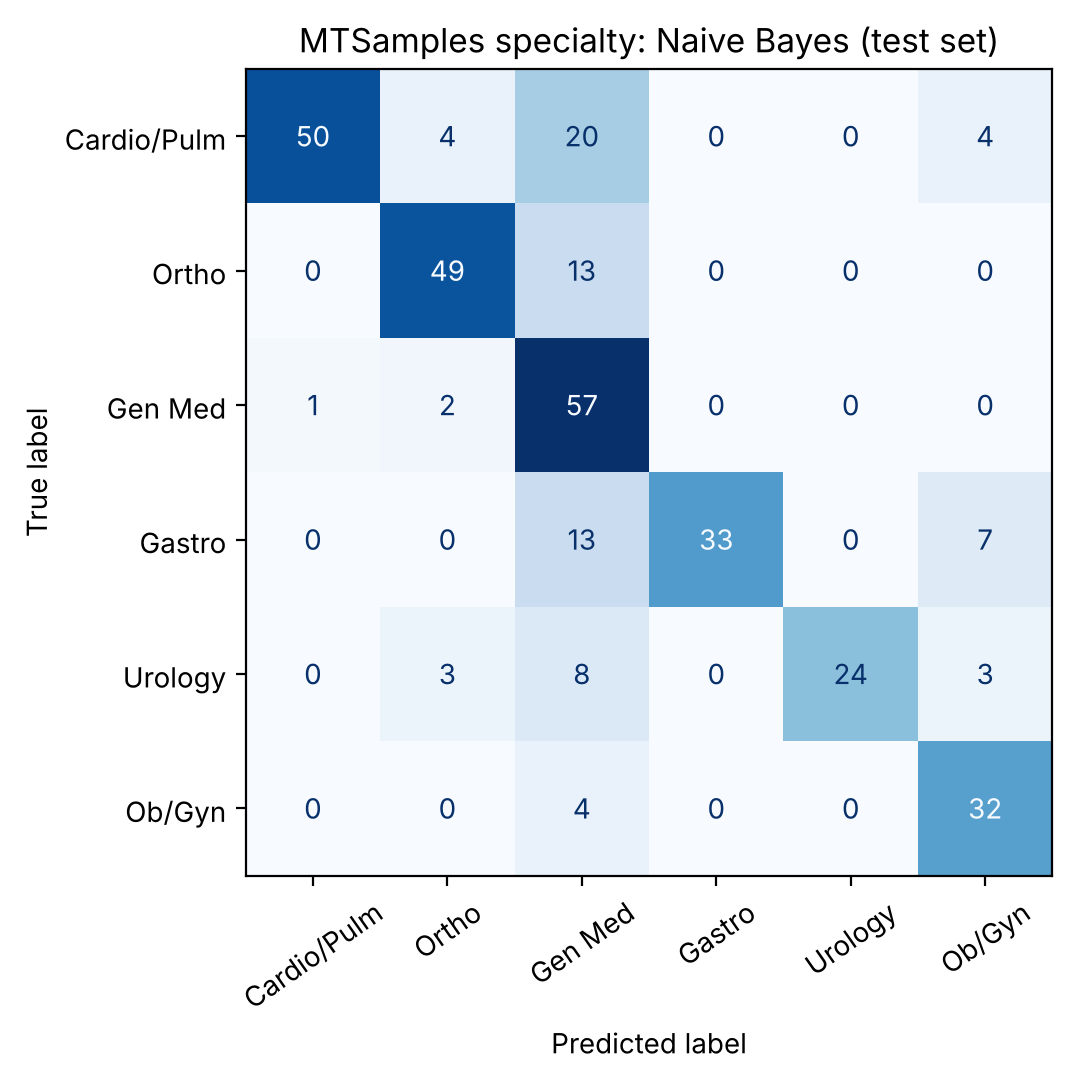

In [13]:
short = {"Cardiovascular / Pulmonary": "Cardio/Pulm", "Orthopedic": "Ortho",
         "General Medicine": "Gen Med", "Gastroenterology": "Gastro",
         "Urology": "Urology", "Obstetrics / Gynecology": "Ob/Gyn"}
cm = metrics.confusion_matrix(y_true, y_pred, labels=top_specialties)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
metrics.ConfusionMatrixDisplay(cm, display_labels=[short.get(s, s) for s in top_specialties]).plot(
    ax=ax, cmap="Blues", colorbar=False, xticks_rotation=35)
ax.set_title("MTSamples specialty: Naive Bayes (test set)")
plt.tight_layout()
fig.savefig(FIGS / "partB_specialty_confusion_matrix.png", dpi=150)
plt.show()

In [14]:
top_words = top_words_per_class(nb_spec, n=10)
top_words_table = pd.DataFrame({short.get(s, s): top_words[s] for s in top_specialties})
top_words_table.to_csv(RESULTS / "partB_top_words_per_specialty.csv", index=False)
top_words_table

,Cardio/Pulm,Ortho,Gen Med,Gastro,Urology,Ob/Gyn
0,ventricular,esmarch,tms,esophagus,scrotal,placenta
1,ventricle,drill,hepatosplenomegaly,colonoscope,scrotum,uterus
2,pigtail,tourniquet,coughing,olympus,urethral,vesicouterine
3,selective,exsanguinated,conjunctivae,antrum,urethra,pfannenstiel
4,angiography,articular,mucous,cecum,psa,apgars
5,gradient,xeroform,equally,esophagogastroduodenoscopy,prostatectomy,cervix
6,circumflex,adaptic,supple,pylorus,meatus,vagina
7,diagonal,splint,nasal,gastroscope,vas,intrauterine
8,catheterization,alignment,xii,video,prostate,fallopian
9,lad,extensor,memory,hiatal,penis,pregnancy


Naive Bayes reaches 0.749 accuracy and 0.761 macro F1, against 0.239 and 0.064 for always predicting the most common specialty. The top words make clinical sense: catheterization, LAD and circumflex for cardiology; tourniquet, drill and splint for orthopaedics; placenta and Pfannenstiel for obstetrics. Being able to read the model like this is the main argument for classic methods.

The weak spot is **General Medicine**. It catches almost all of its own notes (recall 0.95), but only about half of the notes it labels General Medicine actually belong there (precision 0.50). A plausible reason is that general medicine notes are full histories and examinations covering every body system, so their words overlap with every other class. It's the same lopsided pattern as the REAL class in Part A. The test set is small (327 notes, 36–78 per specialty), so the per-class figures are imprecise.

## 5. The same classifier on a second, independent dataset

MTSamples is a single source, so one good split doesn't tell me much about how the method generalises. As a second check I run the identical pipeline on the **Medical Abstracts** corpus: about 14,000 PubMed abstracts labelled with one of five condition groups, using the authors' own train/test split. The labels differ from MTSamples, so this tests the *method* on new data. It is **not** external validation of the MTSamples model.

In [15]:
abs_train = pd.read_csv(DATA / "medical_tc_train.csv")
abs_test = pd.read_csv(DATA / "medical_tc_test.csv")
abs_names = pd.read_csv(DATA / "medical_tc_labels.csv").set_index("condition_label").condition_name.to_dict()
for d in (abs_train, abs_test):
    d["condition"] = d.condition_label.map(abs_names)
print(f"Train abstracts: {len(abs_train):,}   Test abstracts: {len(abs_test):,}")

tr_f, te_f, abs_vocab = build_features(abs_train.medical_abstract, abs_train.condition,
                                       abs_test.medical_abstract, abs_test.condition)
nb_abs = train_naive_bayes(tr_f)
a_true = [y for _, y in te_f]
a_pred = predict(nb_abs, te_f)
a_major = abs_train.condition.value_counts().idxmax()

abs_results = pd.DataFrame([summarise("Naive Bayes", a_true, a_pred),
                            summarise(f"Majority class ({a_major})", a_true, [a_major] * len(a_true))])
abs_results

Train abstracts: 11,550   Test abstracts: 2,888


,model,accuracy,macro F1
0,Naive Bayes,0.533,0.524
1,Majority class (general pathological conditions),0.333,0.100


                                 precision    recall  f1-score   support

                      neoplasms      0.660     0.695     0.677       633
      digestive system diseases      0.392     0.729     0.510       299
        nervous system diseases      0.514     0.556     0.534       385
        cardiovascular diseases      0.537     0.846     0.657       610
general pathological conditions      0.522     0.157     0.242       961

                       accuracy                          0.533      2888
                      macro avg      0.525     0.597     0.524      2888
                   weighted avg      0.541     0.533     0.492      2888



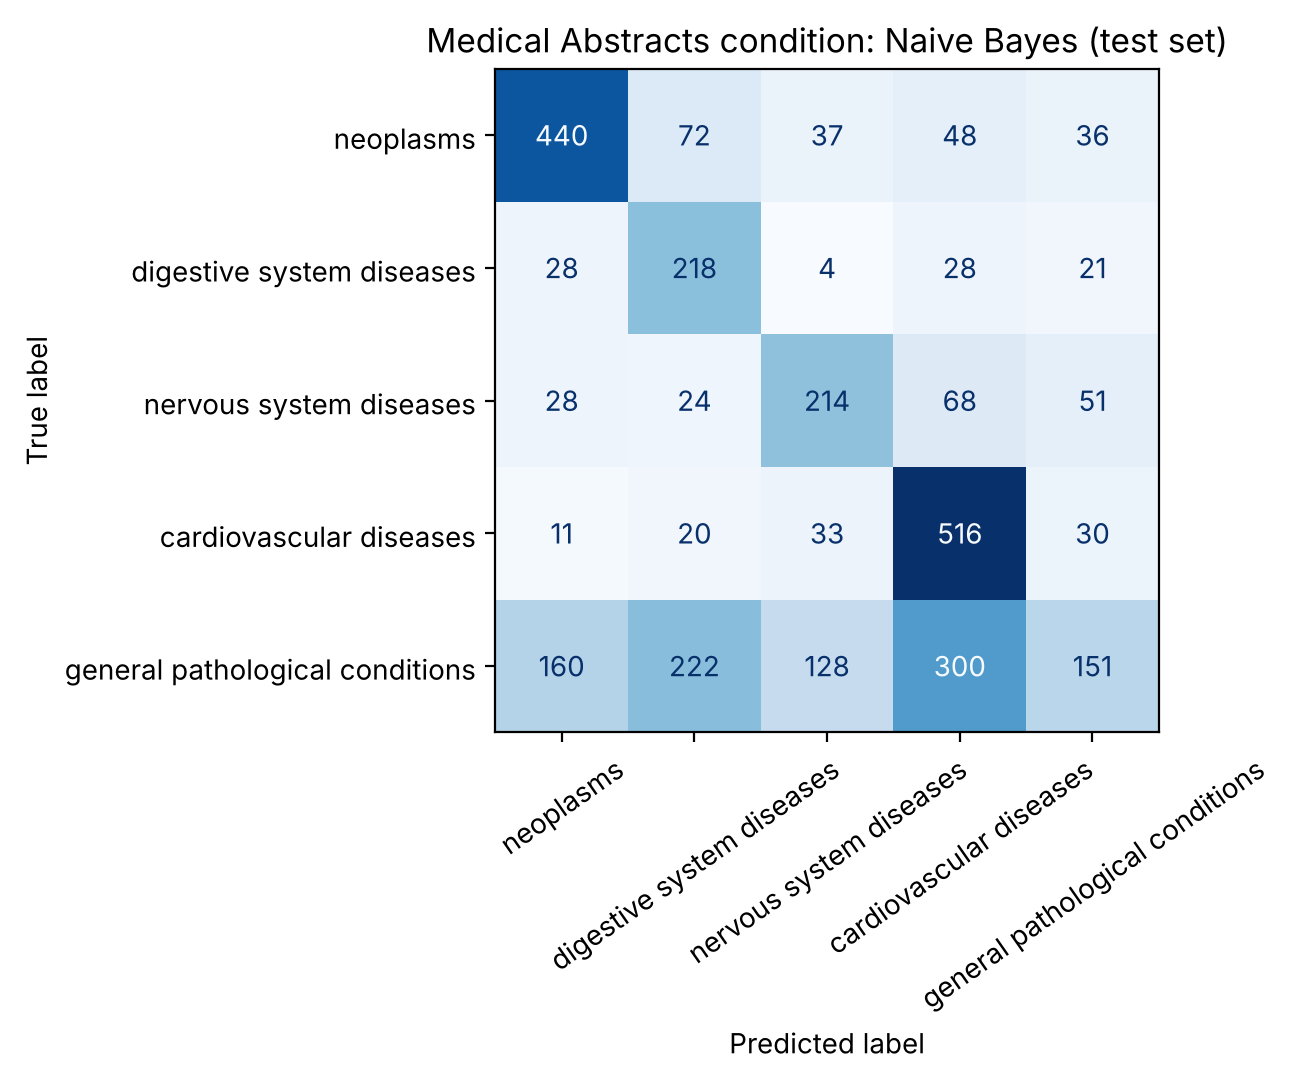

In [16]:
abs_order = list(abs_names.values())
print(metrics.classification_report(a_true, a_pred, labels=abs_order, digits=3, zero_division=0))
fig, ax = plt.subplots(figsize=(6.5, 5.5))
metrics.ConfusionMatrixDisplay.from_predictions(
    a_true, a_pred, labels=abs_order, cmap="Blues", colorbar=False, ax=ax, xticks_rotation=35)
ax.set_title("Medical Abstracts condition: Naive Bayes (test set)")
plt.tight_layout()
fig.savefig(FIGS / "partB_abstracts_confusion_matrix.png", dpi=150)
plt.show()

On the abstracts the same pipeline does worse: 0.533 accuracy and 0.524 macro F1, against 0.333 and 0.100 for the majority baseline. It still clearly beats the baseline, but the gap to MTSamples is large. Most of the drop comes from "general pathological conditions", the largest class, where recall is only 0.157. Like General Medicine in MTSamples, it's a catch-all label that overlaps the other four. Abstracts are also short, which leaves fewer words to go on. The broader point: how well this method works depends heavily on how clean and distinct the labels are, and one dataset alone wouldn't have shown that.

In [17]:
partB = pd.concat([
    pd.DataFrame([{"analysis": "Regex extraction (50 hand-checked matches)", "model": "regex",
                   "metric": "precision", "value": precision.loc["all", "precision"]}]),
    spec_results.melt(id_vars="model", var_name="metric").assign(analysis="MTSamples specialty (6 classes)"),
    abs_results.melt(id_vars="model", var_name="metric").assign(analysis="Medical Abstracts condition (5 classes)"),
])[["analysis", "model", "metric", "value"]]
partB.to_csv(RESULTS / "partB_metrics.csv", index=False)
partB

,analysis,model,metric,value
0,Regex extraction (50 hand-checked matches),regex,precision,0.960
0,MTSamples specialty (6 classes),Naive Bayes,accuracy,0.749
1,MTSamples specialty (6 classes),Majority class (Cardiovascular / Pulmonary),accuracy,0.239
2,MTSamples specialty (6 classes),Naive Bayes,macro F1,0.761
3,MTSamples specialty (6 classes),Majority class (Cardiovascular / Pulmonary),macro F1,0.064
0,Medical Abstracts condition (5 classes),Naive Bayes,accuracy,0.533
1,Medical Abstracts condition (5 classes),Majority class (general pathological conditions),accuracy,0.333
2,Medical Abstracts condition (5 classes),Naive Bayes,macro F1,0.524
3,Medical Abstracts condition (5 classes),Majority class (general pathological conditions),macro F1,0.100
